[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wellingtonmnf/pos-graduacao-ia-ciencia-dados/blob/main/disciplinas/aprendizado-de-maquina/notebooks/unidade-02-classificacao/algoritmo-curva-roc-e-auc.ipynb)


In [1]:
# ============================================================
# CURVA ROC E AUC — Exemplo completo para estudo
# Funciona diretamente no Google Colab sem dados externos
# ============================================================

# --- 1. IMPORTAÇÕES ---
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

# Semente aleatória: garante que você obtenha os mesmos resultados
# toda vez que rodar o código — essencial para estudar e comparar
np.random.seed(42)

In [2]:
# --- 2. CRIAÇÃO DOS DADOS SIMULADOS ---
# make_classification cria um dataset fictício de classificação binária.
# Pense nisso como simular uma planilha com 1000 exemplos de e-mails,
# cada um com 10 características (ex: número de links, palavras suspeitas etc.)
X, y = make_classification(
    n_samples=1000,    # 1000 exemplos (e-mails, pacientes, clientes...)
    n_features=10,     # 10 variáveis de entrada (características)
    n_classes=2,       # 2 classes: 0 = não spam, 1 = spam
    weights=[0.6, 0.4],# 60% da classe 0 e 40% da classe 1 (leve desbalanceamento)
    random_state=42
)

print(f"Total de exemplos: {len(y)}")
print(f"Classe 0 (não spam): {sum(y == 0)} exemplos")
print(f"Classe 1 (spam):     {sum(y == 1)} exemplos")

Total de exemplos: 1000
Classe 0 (não spam): 600 exemplos
Classe 1 (spam):     400 exemplos


Dados simulados: a função `make_classification` cria um dataset fictício com 1000 exemplos e 10 características. Pense nela como uma fábrica de planilhas de dados para fins de estudo. Você pode alterar `n_samples` e `n_features` para experimentar.

In [3]:
print(X.shape)  # Deve mostrar (1000, 10) — 1000 linhas, 10 colunas X = dataset (linhas e colunas)
print(y.shape)  # Deve mostrar (1000,)   — 1000 rótulos, uma dimensão só y = rótulos de cada registro (linha)

(1000, 10)
(1000,)


In [4]:
# --- 3. DIVISÃO TREINO / TESTE ---
# Separamos 30% dos dados para teste — o modelo nunca verá esses dados
# durante o treinamento. É como guardar uma prova surpresa para avaliar
# o aluno depois que ele estudou.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(f"\nDados de treino: {len(y_train)} exemplos")
print(f"Dados de teste:  {len(y_test)} exemplos")


Dados de treino: 700 exemplos
Dados de teste:  300 exemplos


Treino e teste: separamos 30% dos dados para avaliar o modelo depois do treino. É uma prática fundamental em Machine Learning — você nunca avalia o modelo com os mesmos dados que usou para treiná-lo, pois isso seria como dar ao aluno a gabarito antes da prova.

In [5]:
# --- 4. TREINAMENTO DO MODELO ---
# Usamos Regressão Logística — um modelo clássico de classificação.
# Apesar do nome "regressão", ele é usado para classificar!
# Ele gera probabilidades entre 0 e 1 para cada exemplo.
modelo = LogisticRegression(random_state=42)
modelo.fit(X_train, y_train)
print("\nModelo treinado com sucesso!")


Modelo treinado com sucesso!


In [6]:
# --- 5. OBTENDO AS PROBABILIDADES PREVISTAS ---
# predict_proba retorna, para cada exemplo, a probabilidade de
# pertencer à classe 0 e à classe 1.
# Pegamos apenas a coluna da classe 1 (índice [:, 1]).
y_prob = modelo.predict_proba(X_test)[:, 1]

print(f"\nExemplo de probabilidades previstas (primeiros 10 exemplos):")
print(np.round(y_prob[:10], 3))
print(f"Rótulos reais correspondentes: {y_test[:10]}")


Exemplo de probabilidades previstas (primeiros 10 exemplos):
[0.166 0.959 0.249 0.868 0.02  0.942 0.015 0.038 0.124 0.245]
Rótulos reais correspondentes: [0 1 1 1 0 1 0 0 0 0]


`predict_proba`: aqui está a chave que faltava antes. Em vez de pedir ao modelo que diga "spam" ou "não spam" diretamente, pedimos as probabilidades — e são essas probabilidades que alimentam o cálculo da curva ROC.

**IMPORTANTE:** A classificação do modelo não leva em conta apenas as probabilidades, mas também o **LIMIAR DE DECISÃO** (`thresholds`) escolhido para realizar a classificação (0.5 = 50%; 0.2 = 20%; 0.9 = 90%).  

De acordo com o _limiar definido e a probabilidade da amostra_, ela é classificada em um dos subgrupos.

In [7]:
# --- 6. CALCULANDO A AUC ---
auc = roc_auc_score(y_test, y_prob)
print(f"\n{'='*40}")
print(f"  AUC do modelo: {auc:.4f}")
print(f"{'='*40}")


  AUC do modelo: 0.9203


In [8]:
# --- 7. CALCULANDO OS PONTOS DA CURVA ROC ---
# roc_curve varia automaticamente o limiar e calcula
# fpr (taxa de falsos positivos) e tpr (taxa de verdadeiros positivos).
# Os três vetores têm o mesmo comprimento e correspondem por índice.
# O padrão drop_intermediate=True omite pontos colineares sem alterar a AUC.
# O primeiro limiar é infinito: nenhum exemplo é classificado como positivo.
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

print(f"\nNúmero de limiares retornados: {len(thresholds)}")
print(f"Exemplo de limiares (primeiros 5): {np.round(thresholds[:5], 3)}")


Número de limiares testados: 72
Exemplo de limiares (primeiros 5): [  inf 1.    0.976 0.972 0.954]


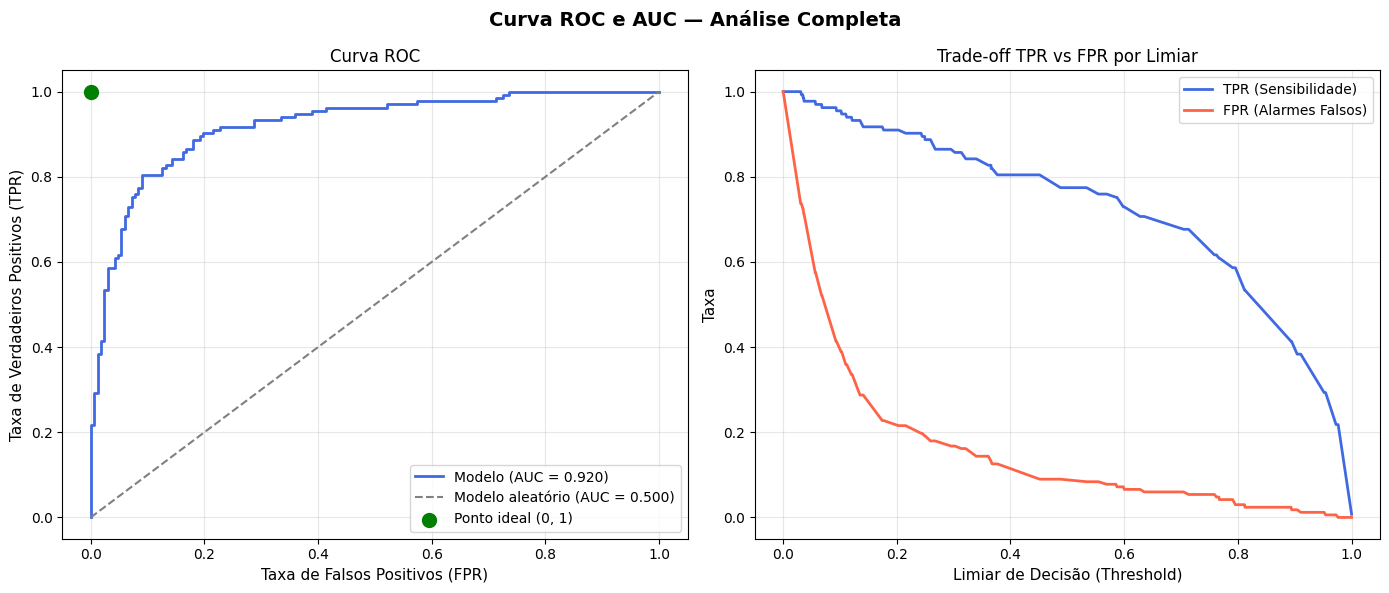

In [9]:
# --- 8. VISUALIZAÇÕES ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Curva ROC e AUC — Análise Completa", fontsize=14, fontweight='bold')

# --- Gráfico 1: A Curva ROC ---
ax1 = axes[0]
ax1.plot(fpr, tpr, color='royalblue', lw=2,
         label=f'Modelo (AUC = {auc:.3f})')
ax1.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--',
         label='Modelo aleatório (AUC = 0.500)')
# Marcando o "ponto ideal" — canto superior esquerdo
ax1.scatter([0], [1], color='green', s=100, zorder=5, label='Ponto ideal (0, 1)')
ax1.set_xlabel('Taxa de Falsos Positivos (FPR)', fontsize=11)
ax1.set_ylabel('Taxa de Verdadeiros Positivos (TPR)', fontsize=11)
ax1.set_title('Curva ROC', fontsize=12)
ax1.legend(loc='lower right')
ax1.grid(alpha=0.3)

# --- Gráfico 2: Como TPR e FPR variam com o limiar ---
# Isso ajuda a visualizar o "trade-off" ao escolher o threshold
ax2 = axes[1]
# O limiar infinito permanece na curva ROC, mas não cabe neste eixo finito.
# A mesma máscara preserva a correspondência entre limiar, TPR e FPR.
limiares_finitos = np.isfinite(thresholds)
ax2.plot(thresholds[limiares_finitos], tpr[limiares_finitos], color='royalblue', lw=2, label='TPR (Sensibilidade)')
ax2.plot(thresholds[limiares_finitos], fpr[limiares_finitos], color='tomato',    lw=2, label='FPR (Alarmes Falsos)')
ax2.set_xlabel('Limiar de Decisão (Threshold)', fontsize=11)
ax2.set_ylabel('Taxa', fontsize=11)
ax2.set_title('Trade-off TPR vs FPR por Limiar', fontsize=12)
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Dois gráficos: o primeiro é a Curva ROC clássica. O segundo é um gráfico extra que eu adicionei especialmente para o seu estudo: ele mostra como TPR e FPR variam conforme você mexe no limiar — o que torna o trade-off visível de forma muito intuitiva.

In [10]:
# --- 9. ENCONTRANDO O LIMIAR IDEAL ---
# Uma estratégia comum é maximizar a diferença entre TPR e FPR.
# Isso representa o ponto onde o modelo discrimina melhor.
diferenca = tpr - fpr
idx_melhor = np.argmax(diferenca)
limiar_ideal = thresholds[idx_melhor]

print(f"\nLimiar ideal encontrado: {limiar_ideal:.3f}")
print(f"  TPR no limiar ideal: {tpr[idx_melhor]:.3f} "
      f"(acertou {tpr[idx_melhor]*100:.1f}% dos positivos reais)")
print(f"  FPR no limiar ideal: {fpr[idx_melhor]:.3f} "
      f"(errou {fpr[idx_melhor]*100:.1f}% dos negativos reais)")


Limiar ideal encontrado: 0.451
  TPR no limiar ideal: 0.805 (acertou 80.5% dos positivos reais)
  FPR no limiar ideal: 0.090 (errou 9.0% dos negativos reais)


Limiar ideal: aqui buscamos automaticamente o threshold onde a diferença entre "acertos nos positivos" e "alarmes falsos" é máxima. É uma das formas mais práticas de escolher onde operar o modelo.

In [11]:
print("Limiar       FPR        TPR")
print("-" * 35)
for i in range(0, min(10, len(thresholds))):
    print(f"  {thresholds[i]:.3f}      {fpr[i]:.3f}      {tpr[i]:.3f}")

Limiar       FPR        TPR
-----------------------------------
  inf      0.000      0.000
  1.000      0.000      0.008
  0.976      0.000      0.218
  0.972      0.006      0.218
  0.954      0.006      0.293
  0.951      0.012      0.293
  0.910      0.012      0.383
  0.904      0.018      0.383
  0.894      0.018      0.414
  0.893      0.024      0.414


## O que é `thresholds`

`thresholds` é exatamente o vetor de **limiares de decisão** — cada valor nele representa um ponto de corte que o modelo usa para decidir: *"a partir de qual probabilidade eu classifico este exemplo como positivo (classe 1)?"*

O modelo não entrega diretamente "spam" ou "não spam". Ele entrega uma probabilidade — por exemplo, `0.73`. Quem decide o que fazer com esse `0.73` é o limiar. Se o limiar for `0.5`, esse exemplo vira "spam". Se o limiar for `0.8`, esse mesmo exemplo vira "não spam".

## O que `roc_curve` faz com os thresholds

A função `roc_curve` automatiza um processo que, manualmente, seria tedioso. Ela calcula FPR e TPR a partir dos escores únicos previstos. Por padrão, `drop_intermediate=True` omite pontos intermediários colineares, preservando a forma da curva e sua AUC; assim, nem todo escore único aparece no retorno. Para inspecionar todos os limiares, é possível usar `drop_intermediate=False`. O resultado são três vetores de mesmo comprimento, alinhados entre si:

```
thresholds[i]  →  fpr[i]  e  tpr[i]
```

Ou seja, para o limiar de valor `thresholds[i]`, o modelo teria uma taxa de falsos positivos igual a `fpr[i]` e uma taxa de verdadeiros positivos igual a `tpr[i]`. Cada ponto da Curva ROC que você vê no gráfico é exatamente um desses trios.

## Visualizando o efeito do limiar

Imagine que seu modelo gerou as seguintes probabilidades para 5 exemplos:

```
Exemplo   Probabilidade   Rótulo real
   A          0.91            1  (spam)
   B          0.74            1  (spam)
   C          0.55            0  (não spam)
   D          0.32            1  (spam)
   E          0.18            0  (não spam)
```

Agora observe como o limiar muda as classificações — e consequentemente os erros:

**Limiar = 0.90** → só o exemplo A vira spam. O modelo é muito conservador. Pega poucos spams (TPR baixo), mas quase não erra e-mails legítimos (FPR baixo).

**Limiar = 0.50** → A, B e C viram spam. O modelo começa a errar C (que era legítimo) — um falso positivo. TPR sobe, FPR também sobe.

**Limiar = 0.10** → todos viram spam. O modelo pega todos os spams reais (TPR = 100%), mas também erra todos os legítimos (FPR = 100%). Inútil pelo excesso oposto.

Esse movimento é exatamente o **trade-off** que a Curva ROC captura visualmente — conforme o limiar cai, TPR e FPR sobem juntos, e a curva "caminha" da origem (0,0) até o canto superior direito (1,1).

## O vetor `thresholds` na prática

Você pode adicionar este bloco ao seu código para tornar isso concreto e observável:

```python
print("Limiar       FPR        TPR")
print("-" * 35)
for i in range(0, min(10, len(thresholds))):
    print(f"  {thresholds[i]:.3f}      {fpr[i]:.3f}      {tpr[i]:.3f}")
```

Ao rodar, você verá que conforme o limiar diminui, o FPR e o TPR tendem a crescer juntos — exatamente o trade-off que discutimos.

## Um detalhe técnico importante

O scikit-learn ordena os thresholds do **maior para o menor**. O primeiro limiar é `np.inf`: nenhum exemplo é classificado como positivo e a curva começa em (0, 0). O último limiar corresponde ao menor escore observado: todos os exemplos são classificados como positivos, chegando a (1, 1). O gráfico de taxas por limiar usa apenas os limiares finitos, aplicando a mesma máscara a `thresholds`, `fpr` e `tpr`; a curva ROC mantém todos os pontos retornados.

## Resumindo

`thresholds` é o mecanismo que transforma probabilidades contínuas (números entre 0 e 1) em decisões binárias (positivo ou negativo). A Curva ROC existe justamente para responder: *"qual é o comportamento do meu modelo para cada possível escolha de limiar?"* — e a AUC resume esse comportamento em um único número. Você escolhe o threshold ideal **depois** de entender a curva, em função do que o seu problema tolera mais: falsos positivos ou falsos negativos.

Quando você rodar, espere uma AUC em torno de 0.85 a 0.90 — o que é um resultado muito bom para dados simulados. Tente mudar o `random_state=42` para outro número (como `random_state=7`) e observe como a AUC muda levemente. Isso é um ótimo exercício para entender que o resultado sempre depende dos dados!